**รายชื่อสมาชิก**
  

1.   สิริภัท ธนสุขโสภณ 6809540179
2.   ภณวรรชน์ โขงเขตต์ 6809617282
3.   รมณ ประภาพรสุข 6809617332   
4.   วิรมณ มาเกิด 6809617407   
5.   อานัส บินเสะ 6809617522   
6.   ณพวุฒิ วิทยากุล 6809681429   
7.   ปาณิศรา แวงดิศร 6809681452   
8.   ศรัณย์วิชญ์ โพธิ์ชัย 6809681478   
9.   อานนท์ พูนสิน 6809681494   


In [ ]:
# Import libraries
from google.colab import drive
import pandas as pd
import numpy as np
import glob
import os

## Problem Framing and Data Collection

**หัวข้อเรื่อง : ปัจจัยที่ส่งผลต่อความอันตรายของอุบัติเหตุทางท้องถนน**

วัตถุประสงค์ (Objectives)

แหล่งที่มาของข้อมูล จากเว็บไซต์ ระบบบัญชีข้อมูลด้านคมนาคม MOT Data Catalog หัวข้อ อุบัติเหตุบนโครงข่ายถนนของกระทรวงคมนาคม https://datagov.mot.go.th/dataset/roadaccident

#Data Acquisition

ข้อมูลอุบัติเหตุทางถนนระหว่างปี 2020–2026 จำนวน 7 ไฟล์

In [ ]:
# Connect to Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
files = sorted(
    glob.glob(
        "/content/drive/MyDrive/**/accident*.csv",
        recursive=True
    )
)

print("พบไฟล์:", len(files))

for file in files:
    print(os.path.basename(file))

พบไฟล์: 7
accident2020.csv
accident2021.csv
accident2022.csv
accident2023.csv
accident2024.csv
accident2025.csv
accident2026.csv


In [ ]:
column_map = {
    "ปีที่เกิดเหตุ": "accident_year",
    "วันที่เกิดเหตุ": "accident_date",
    "เวลา": "accident_time",
    "วันที่รายงาน": "report_date",
    "เวลาที่รายงาน": "report_time",

    "ACC_CODE": "accident_code",
    "หน่วยงาน": "agency",
    "สายทางหน่วยงาน": "road_agency",
    "รหัสสายทาง": "road_code",
    "สายทาง": "road_name",

    "KM": "kilometer",
    "ก.ม.": "kilometer",

    "จังหวัด": "province",
    "รถคันที่1": "first_vehicle",

    "บริเวณที่เกิดเหตุ": "accident_location",
    "บริเวณที่เกิดเหตุ/ลักษณะทาง": "accident_location",
    "บริเวณที่เกิดเหตุอื่น": "accident_location_other",

    "มูลเหตุสันนิษฐาน": "suspected_cause",

    "ลักษณะการเกิดเหตุ": "accident_type",
    "ลักษณะการเกิดอุบัติเหตุ": "accident_type",

    "สภาพอากาศ": "weather",
    "LATITUDE": "latitude",
    "LONGITUDE": "longitude",

    "รถที่เกิดเหตุ": "vehicle_count",
    "จำนวนรถที่เกิดเหตุ(รวมคันที่1)": "vehicle_count",

    "รถและคนที่เกิดเหตุ": "involved_count",
    "จำนวนที่เกิดเหตุทั้งหมด(รวมคนเดินเท้า)": "involved_count",

    "รถจักรยานยนต์": "motorcycle_count",
    "รถสามล้อเครื่อง": "motor_tricycle_count",

    "รถยนต์นั่งส่วนบุคคล": "passenger_car_count",
    "รถยนต์นั่งส่วนบุคคล/รถยนต์นั่งสาธารณะ":
        "passenger_car_count",

    "รถตู้": "van_count",
    "รถปิคอัพโดยสาร": "passenger_pickup_count",

    "รถโดยสารมากกว่า4ล้อ":
        "bus_over_4_wheels_count",

    "รถปิคอัพบรรทุก4ล้อ":
        "cargo_pickup_4_wheels_count",

    "รถบรรทุก6ล้อ":
        "truck_6_wheels_count",

    "รถบรรทุกไม่เกิน10ล้อ":
        "truck_7_to_10_wheels_count",

    "รถบรรทุกมากกว่า6ล้อไม่เกิน10ล้อ":
        "truck_7_to_10_wheels_count",

    "รถบรรทุกมากกว่า10ล้อ":
        "truck_over_10_wheels_count",

    "รถบรรทุกมากกว่า10ล้อ(รถพ่วง)":
        "truck_over_10_wheels_count",

    "รถอีแต๋น": "farm_truck_count",

    "รถอื่นๆ": "other_vehicle_count",
    "อื่นๆ": "other_vehicle_count",

    "คนเดินเท้า": "pedestrian_count",

    "ผู้เสียชีวิต": "fatality_count",
    "จำนวนผู้เสียชีวิต": "fatality_count",

    "ผู้บาดเจ็บสาหัส": "serious_injury_count",
    "จำนวนผู้บาดเจ็บสาหัส": "serious_injury_count",

    "ผู้บาดเจ็บเล็กน้อย": "minor_injury_count",
    "จำนวนผู้บาดเจ็บเล็กน้อย": "minor_injury_count",

    "รวมจำนวนผู้บาดเจ็บ": "total_injury_count"
}

In [ ]:
# Convert Excel serial date to date text
# ตัวอย่าง 45292 -> 1/1/2024

def excel_date_to_text(series):
    numeric_values = pd.to_numeric(
        series,
        errors="coerce"
    )

    converted_dates = pd.to_datetime(
        numeric_values,
        unit="D",
        origin="1899-12-30",
        errors="coerce"
    )

    return converted_dates.map(
        lambda value:
        f"{value.day}/{value.month}/{value.year}"
        if pd.notna(value)
        else pd.NA
    )


# Convert Excel time fraction to HH:MM
# ตัวอย่าง 0.008333333 -> 00:12

def excel_time_to_text(series):
    numeric_values = pd.to_numeric(
        series,
        errors="coerce"
    )

    total_minutes = np.rint(
        numeric_values * 24 * 60
    )

    def format_time(value):
        if pd.isna(value):
            return pd.NA

        value = int(value) % 1440

        hour = value // 60
        minute = value % 60

        return f"{hour:02d}:{minute:02d}"

    return total_minutes.map(format_time)

In [ ]:
# Read and standardize each yearly CSV file

frames = []

for file in files:
    temp_df = pd.read_csv(file)

    # Remove spaces from column names
    temp_df.columns = temp_df.columns.str.strip()

    # Get year from filename
    # เช่น accident2024.csv -> 2024
    file_year = int(
        os.path.basename(file)
        .replace("accident", "")
        .replace(".csv", "")
    )

    # Year 2024:
    # Convert accident/report dates and times
    if file_year == 2024:
        temp_df["วันที่เกิดเหตุ"] = (
            excel_date_to_text(
                temp_df["วันที่เกิดเหตุ"]
            )
        )

        temp_df["วันที่รายงาน"] = (
            excel_date_to_text(
                temp_df["วันที่รายงาน"]
            )
        )

        temp_df["เวลา"] = (
            excel_time_to_text(
                temp_df["เวลา"]
            )
        )

        temp_df["เวลาที่รายงาน"] = (
            excel_time_to_text(
                temp_df["เวลาที่รายงาน"]
            )
        )

    # Year 2025:
    # Convert accident/report dates only
    elif file_year == 2025:
        temp_df["วันที่เกิดเหตุ"] = (
            excel_date_to_text(
                temp_df["วันที่เกิดเหตุ"]
            )
        )

        temp_df["วันที่รายงาน"] = (
            excel_date_to_text(
                temp_df["วันที่รายงาน"]
            )
        )

    # Rename columns to English
    temp_df = temp_df.rename(
        columns=column_map
    )

    frames.append(temp_df)


# Combine all years
df = pd.concat(
    frames,
    ignore_index=True
)

print("ขนาดข้อมูลรวม:", df.shape)
print("จำนวนคอลัมน์:", len(df.columns))

ขนาดข้อมูลรวม: (151823, 39)
จำนวนคอลัมน์: 39


In [ ]:
# Convert date columns of every year to datetime

date_columns = [
    "accident_date",
    "report_date"
]

for column in date_columns:
    df[column] = pd.to_datetime(
        df[column],
        format="mixed",
        dayfirst=True,
        errors="coerce"
    )

In [ ]:
# Standardize time columns to HH:MM

def normalize_time(series):
    time_parts = (
        series
        .astype("string")
        .str.extract(
            r"^\s*(\d{1,2}):(\d{1,2})"
            r"(?::\d{1,2})?\s*$"
        )
    )

    hours = pd.to_numeric(
        time_parts[0],
        errors="coerce"
    )

    minutes = pd.to_numeric(
        time_parts[1],
        errors="coerce"
    )

    valid_time = (
        hours.between(0, 23)
        & minutes.between(0, 59)
    )

    result = pd.Series(
        pd.NA,
        index=series.index,
        dtype="string"
    )

    result.loc[valid_time] = (
        hours.loc[valid_time]
        .astype(int)
        .astype(str)
        .str.zfill(2)
        + ":"
        + minutes.loc[valid_time]
        .astype(int)
        .astype(str)
        .str.zfill(2)
    )

    return result


time_columns = [
    "accident_time",
    "report_time"
]

for column in time_columns:
    df[column] = normalize_time(
        df[column]
    )

In [ ]:
display(
    df.loc[
        df["accident_year"].isin(
            [2024, 2025]
        ),
        [
            "accident_year",
            "accident_date",
            "accident_time",
            "report_date",
            "report_time"
        ]
    ].head(20)
)

,accident_year,accident_date,accident_time,report_date,report_time
85708,2024,2024-01-01,00:12,2024-06-18,14:23
85709,2024,2024-01-01,00:30,2024-01-01,12:13
85710,2024,2024-01-01,00:30,2024-01-02,04:18
85711,2024,2024-01-01,00:30,2024-01-01,11:40
85712,2024,2024-01-01,00:30,2024-01-02,05:10
85713,2024,2024-01-01,00:30,2024-01-02,12:29
85714,2024,2024-01-01,00:30,2024-01-02,12:28
85715,2024,2024-01-01,00:30,2024-03-05,13:28
85716,2024,2024-01-01,00:30,2024-03-27,11:29
85717,2024,2024-01-01,00:30,2024-11-21,11:43


In [ ]:
print(
    df[
        [
            "accident_date",
            "accident_time",
            "report_date",
            "report_time"
        ]
    ].dtypes
)

accident_date    datetime64[ns]
accident_time    string[python]
report_date      datetime64[ns]
report_time      string[python]
dtype: object


# Data Preparation: Data Cleaning

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 151823 entries, 0 to 151822
Data columns (total 39 columns):
 #   Column                       Non-Null Count   Dtype         
---  ------                       --------------   -----         
 0   accident_year                151823 non-null  int64         
 1   accident_date                151822 non-null  datetime64[ns]
 2   accident_time                151822 non-null  string        
 3   report_date                  151740 non-null  datetime64[ns]
 4   report_time                  151735 non-null  string        
 5   accident_code                133375 non-null  float64       
 6   agency                       151823 non-null  object        
 7   road_agency                  151823 non-null  object        
 8   road_code                    151811 non-null  object        
 9   road_name                    129597 non-null  object        
 10  kilometer                    150626 non-null  float64       
 11  province                  

In [ ]:
print(df.columns.tolist())

['accident_year', 'accident_date', 'accident_time', 'report_date', 'report_time', 'accident_code', 'agency', 'road_agency', 'road_code', 'road_name', 'kilometer', 'province', 'first_vehicle', 'accident_location', 'suspected_cause', 'accident_type', 'weather', 'latitude', 'longitude', 'vehicle_count', 'involved_count', 'motorcycle_count', 'motor_tricycle_count', 'passenger_car_count', 'van_count', 'passenger_pickup_count', 'bus_over_4_wheels_count', 'cargo_pickup_4_wheels_count', 'truck_6_wheels_count', 'truck_7_to_10_wheels_count', 'truck_over_10_wheels_count', 'farm_truck_count', 'other_vehicle_count', 'pedestrian_count', 'fatality_count', 'serious_injury_count', 'minor_injury_count', 'total_injury_count', 'accident_location_other']


In [ ]:
print(
    "ชื่อคอลัมน์ไม่ซ้ำ:",
    df.columns.is_unique
)

ชื่อคอลัมน์ไม่ซ้ำ: True


In [ ]:
year_counts = (
    df["accident_year"]
    .value_counts()
    .sort_index()
)

display(year_counts)

,count
accident_year,
2020,21239
2021,20062
2022,20566
2023,23841
2024,23952
2025,23715
2026,18448


In [ ]:
duplicate_count = df.duplicated().sum()

print("จำนวนแถวซ้ำ:", duplicate_count)

จำนวนแถวซ้ำ: 83


In [ ]:
df_clean = df.copy()

In [ ]:
text_columns = df_clean.select_dtypes(
    include=["object", "string"]
).columns

for column in text_columns:
    df_clean[column] = (
        df_clean[column]
        .astype("string")
        .str.strip()
    )

In [ ]:
df_clean = df_clean.replace(
    {
        "": np.nan,
        "-": np.nan,
        "ไม่ทราบ": np.nan,
        "ไม่มีข้อมูล": np.nan
    }
)

In [ ]:
df_clean = (
    df_clean
    .drop_duplicates()
    .reset_index(drop=True)
)

print("ขนาดก่อน Clean:", df.shape)
print("ขนาดหลัง Clean:", df_clean.shape)
print(
    "ข้อมูลซ้ำที่เหลือ:",
    df_clean.duplicated().sum()
)

ขนาดก่อน Clean: (151823, 39)
ขนาดหลัง Clean: (151740, 39)
ข้อมูลซ้ำที่เหลือ: 0


In [ ]:
date_columns = [
    "accident_date",
    "report_date"
]

for column in date_columns:
    df_clean[column] = pd.to_datetime(
        df_clean[column],
        format="mixed",
        dayfirst=True,
        errors="coerce"
    )

print(df_clean[date_columns].dtypes)

accident_date    datetime64[ns]
report_date      datetime64[ns]
dtype: object


In [ ]:
df_clean["accident_code"] = (
    pd.to_numeric(
        df_clean["accident_code"],
        errors="coerce"
    )
    .astype("Int64")
)

In [ ]:
missing_values = (
    df_clean.isnull()
    .sum()
    .sort_values(ascending=False)
)

display(
    missing_values[
        missing_values > 0
    ]
)

,0
accident_location_other,133859
road_name,22226
accident_code,18426
accident_location,12887
accident_type,8508
suspected_cause,2884
first_vehicle,2286
province,1958
kilometer,1186
longitude,947


In [ ]:
print("ค่าใน agency")

display(
    df_clean["agency"]
    .value_counts(dropna=False)
)

ค่าใน agency


,count
agency,
กรมทางหลวง,140956
กรมทางหลวงชนบท,7908
การทางพิเศษแห่งประเทศไทย,2876


In [ ]:
print("ค่าใน road_agency")

display(
    df_clean["road_agency"]
    .value_counts(dropna=False)
)

ค่าใน road_agency


,count
road_agency,
ทางหลวง,140956
ทางหลวงชนบท,7908
การทางพิเศษ,2876


In [ ]:
print("ขนาดข้อมูลสุดท้าย:", df_clean.shape)
print(
    "จำนวนข้อมูลซ้ำ:",
    df_clean.duplicated().sum()
)

df_clean.info()

ขนาดข้อมูลสุดท้าย: (151740, 39)
จำนวนข้อมูลซ้ำ: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 151740 entries, 0 to 151739
Data columns (total 39 columns):
 #   Column                       Non-Null Count   Dtype         
---  ------                       --------------   -----         
 0   accident_year                151740 non-null  int64         
 1   accident_date                151739 non-null  datetime64[ns]
 2   accident_time                151739 non-null  string        
 3   report_date                  151657 non-null  datetime64[ns]
 4   report_time                  151652 non-null  string        
 5   accident_code                133314 non-null  Int64         
 6   agency                       151740 non-null  string        
 7   road_agency                  151740 non-null  string        
 8   road_code                    151728 non-null  string        
 9   road_name                    129514 non-null  string        
 10  kilometer                    150554 non-nu

In [ ]:
display(df_clean.head())

,accident_year,accident_date,accident_time,report_date,report_time,accident_code,agency,road_agency,road_code,road_name,...,truck_7_to_10_wheels_count,truck_over_10_wheels_count,farm_truck_count,other_vehicle_count,pedestrian_count,fatality_count,serious_injury_count,minor_injury_count,total_injury_count,accident_location_other
0,2020,2020-01-01,00:05,2020-01-01,08:07,3785916,กรมทางหลวง,ทางหลวง,4225,สวนปาล์ม -คลองชี,...,0,0,0,0,1,0,1,0,1,<NA>
1,2020,2020-01-01,00:05,2020-02-01,00:36,3786314,กรมทางหลวง,ทางหลวง,3473,หนองจิกรี - ถนนสุด,...,0,0,0,0,0,0,1,0,1,<NA>
2,2020,2020-01-01,00:15,2020-02-01,06:06,575019,กรมทางหลวงชนบท,ทางหลวงชนบท,นภ.3038,ถนนผังเมืองรวมเมืองหนองบัวลำภู สาย ข,...,0,0,0,0,0,1,0,0,0,<NA>
3,2020,2020-01-01,00:15,2021-01-20,07:46,3814981,กรมทางหลวง,ทางหลวง,302,แยกพงษ์เพชร - สะพานพระนั่งเกล้า,...,0,0,0,0,0,0,0,1,1,<NA>
4,2020,2020-01-01,00:20,2020-03-02,13:23,3789099,กรมทางหลวง,ทางหลวง,2196,นางั่ว - ทุ่งสมอ,...,0,0,0,0,0,0,1,0,1,<NA>


# ข้อมูลคุณลักษณะ:


# **Data Preparation: Data Encoding**

In [ ]:
# 1) รวมชื่อจังหวัดที่สะกดไม่เหมือนกันให้เป็นมาตรฐานเดียว และเช็กชื่อจังหวัด
df_clean["province"] = df_clean["province"].replace({
    "อยุธยา": "พระนครศรีอยุธยา"
})
print(sorted(df_clean["province"].dropna().unique()))
print("จำนวนจังหวัด (ไม่รวมค่าว่าง):", df_clean["province"].nunique(dropna=True))

# 2) ล้างพิกัดที่อยู่นอกประเทศไทยให้เป็น NaN
invalid_geo = ~(
    df_clean["latitude"].between(5.5, 20.6) &
    df_clean["longitude"].between(97.3, 105.7)
)
df_clean.loc[invalid_geo, ["latitude", "longitude"]] = np.nan

['กระบี่', 'กรุงเทพมหานคร', 'กาญจนบุรี', 'กาฬสินธุ์', 'กำแพงเพชร', 'ขอนแก่น', 'จันทบุรี', 'ฉะเชิงเทรา', 'ชลบุรี', 'ชัยนาท', 'ชัยภูมิ', 'ชุมพร', 'ตรัง', 'ตราด', 'ตาก', 'นครนายก', 'นครปฐม', 'นครพนม', 'นครราชสีมา', 'นครศรีธรรมราช', 'นครสวรรค์', 'นนทบุรี', 'นราธิวาส', 'น่าน', 'บึงกาฬ', 'บุรีรัมย์', 'ปทุมธานี', 'ประจวบคีรีขันธ์', 'ปราจีนบุรี', 'ปัตตานี', 'พระนครศรีอยุธยา', 'พะเยา', 'พังงา', 'พัทลุง', 'พิจิตร', 'พิษณุโลก', 'ภูเก็ต', 'มหาสารคาม', 'มุกดาหาร', 'ยะลา', 'ยโสธร', 'ระนอง', 'ระยอง', 'ราชบุรี', 'ร้อยเอ็ด', 'ลพบุรี', 'ลำปาง', 'ลำพูน', 'ศรีสะเกษ', 'สกลนคร', 'สงขลา', 'สตูล', 'สมุทรปราการ', 'สมุทรสงคราม', 'สมุทรสาคร', 'สระบุรี', 'สระแก้ว', 'สิงห์บุรี', 'สุพรรณบุรี', 'สุราษฎร์ธานี', 'สุรินทร์', 'สุโขทัย', 'หนองคาย', 'หนองบัวลำภู', 'อำนาจเจริญ', 'อุดรธานี', 'อุตรดิตถ์', 'อุทัยธานี', 'อุบลราชธานี', 'อ่างทอง', 'เชียงราย', 'เชียงใหม่', 'เพชรบุรี', 'เพชรบูรณ์', 'เลย', 'แพร่', 'แม่ฮ่องสอน']
จำนวนจังหวัด (ไม่รวมค่าว่าง): 77


In [ ]:
df_encoded = df_clean.copy()

print("ขนาดข้อมูล:", df_encoded.shape)

ขนาดข้อมูล: (151740, 39)


In [ ]:
df_encoded = df_encoded.drop(
    columns=["road_agency"],
    errors="ignore"
)

In [ ]:
categorical_columns = [
    "agency",
    "province",
    "first_vehicle",
    "accident_location",
    "suspected_cause",
    "accident_type",
    "weather"
]

In [ ]:
for column in categorical_columns:
    print(
        column,
        "=",
        df_clean[column].nunique(),
        "ประเภท"
    )

agency = 3 ประเภท
province = 77 ประเภท
first_vehicle = 15 ประเภท
accident_location = 88 ประเภท
suspected_cause = 119 ประเภท
accident_type = 152 ประเภท
weather = 6 ประเภท


In [ ]:
for column in categorical_columns:
    df_encoded[column] = (
        df_encoded[column]
        .astype("string")
        .fillna("Unknown")
    )

In [ ]:
df_encoded = pd.get_dummies(
    df_encoded,
    columns=categorical_columns,
    prefix=categorical_columns,
    prefix_sep="_",
    drop_first=False,
    dtype="int8"
)

In [ ]:
print("ขนาดก่อน Encoding:", df_clean.shape)
print("ขนาดหลัง Encoding:", df_encoded.shape)

display(df_encoded.head())

ขนาดก่อน Encoding: (151740, 39)
ขนาดหลัง Encoding: (151740, 497)


,accident_year,accident_date,accident_time,report_date,report_time,accident_code,road_code,road_name,kilometer,latitude,...,accident_type_แซงขวาชนกับรถเลี้ยวขวา,accident_type_แซงไม่พ้น หักชนรถที่ถูกแซง,accident_type_ไม่มีรายละเอียด,weather_Unknown,weather_ฝนตก,weather_ภัยธรรมชาติ เช่น พายุ น้ำท่วม,weather_มีหมอก/ควัน/ฝุ่น,weather_มืดครึ้ม,weather_อื่นๆ,weather_แจ่มใส
0,2020,2020-01-01,00:05,2020-01-01,08:07,3785916,4225,สวนปาล์ม -คลองชี,6.600,8.008887,...,0,0,0,0,0,0,0,0,0,1
1,2020,2020-01-01,00:05,2020-02-01,00:36,3786314,3473,หนองจิกรี - ถนนสุด,37.000,15.650940,...,0,0,0,0,0,0,0,0,0,1
2,2020,2020-01-01,00:15,2020-02-01,06:06,575019,นภ.3038,ถนนผังเมืองรวมเมืองหนองบัวลำภู สาย ข,7.275,17.191475,...,0,0,0,0,0,0,0,0,0,1
3,2020,2020-01-01,00:15,2021-01-20,07:46,3814981,302,แยกพงษ์เพชร - สะพานพระนั่งเกล้า,7.995,13.861192,...,0,0,0,0,0,0,0,0,0,1
4,2020,2020-01-01,00:20,2020-03-02,13:23,3789099,2196,นางั่ว - ทุ่งสมอ,29.300,16.609966,...,0,0,0,0,0,0,0,0,0,1


In [ ]:
remaining_text_columns = (
    df_encoded
    .select_dtypes(include=["object", "string"])
    .columns
    .tolist()
)

print(
    "คอลัมน์ข้อความที่เหลือ:",
    remaining_text_columns
)

คอลัมน์ข้อความที่เหลือ: ['accident_time', 'report_time', 'road_code', 'road_name', 'accident_location_other']


# Data Preparation: EDA

In [ ]:
!apt-get -qq -y install fonts-thai-tlwg
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.font_manager as fm

font_path = "/usr/share/fonts/truetype/tlwg/Waree.ttf"
fm.fontManager.addfont(font_path)
plt.rcParams["font.family"] = "Waree"
plt.rcParams["axes.unicode_minus"] = False

# แปลงวันที่และแยกเดือน / วันในสัปดาห์ / ชั่วโมง
df_clean['accident_date'] = pd.to_datetime(df_clean['accident_date'], errors='coerce')
df_clean['month'] = df_clean['accident_date'].dt.month
df_clean['day_of_week'] = df_clean['accident_date'].dt.day_name()
df_clean['hour'] = pd.to_numeric(df_clean['accident_time'].astype(str).str.split(':').str[0], errors='coerce')

# สร้างตัวแปร 1 = มีผู้เสียชีวิต, 0 = ไม่มีผู้เสียชีวิต
df_clean['is_fatal'] = (df_clean['fatality_count'] > 0).astype(int)

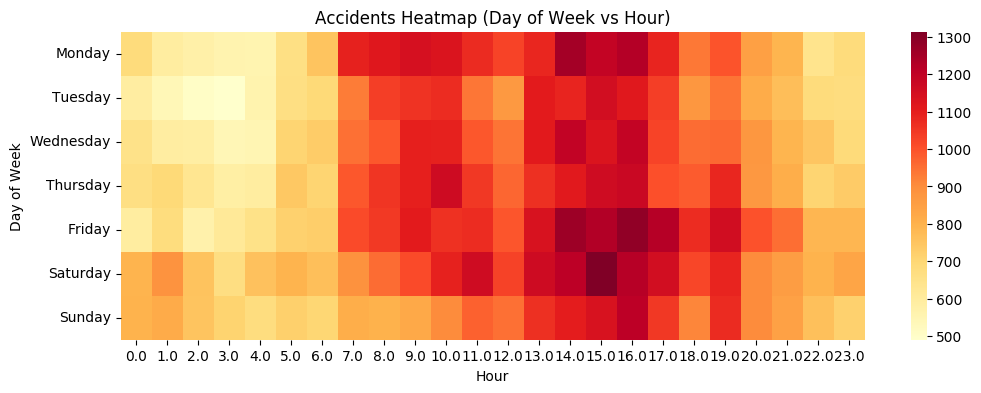

In [ ]:
#Heatmap: วันในสัปดาห์ × ชั่วโมง
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
heat_data = df_clean.pivot_table(index='day_of_week', columns='hour', values='is_fatal', aggfunc='count').reindex(day_order)

plt.figure(figsize=(12,4))
sns.heatmap(heat_data, cmap='YlOrRd')
plt.title("Accidents Heatmap (Day of Week vs Hour)")
plt.xlabel("Hour")
plt.ylabel("Day of Week")
plt.show()

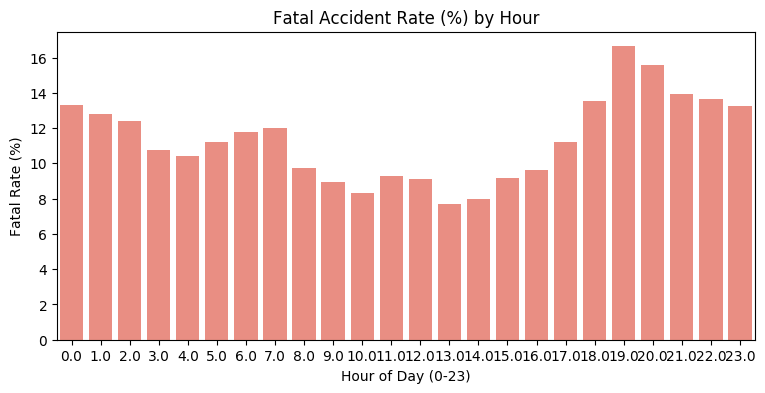

In [ ]:
#อัตราการเสียชีวิต (%) ในแต่ละชั่วโมง
hourly_fatal = df_clean.groupby('hour')['is_fatal'].mean() * 100

plt.figure(figsize=(9,4))
sns.barplot(x=hourly_fatal.index, y=hourly_fatal.values, color='salmon')
plt.title("Fatal Accident Rate (%) by Hour")
plt.xlabel("Hour of Day (0-23)")
plt.ylabel("Fatal Rate (%)")
plt.show()

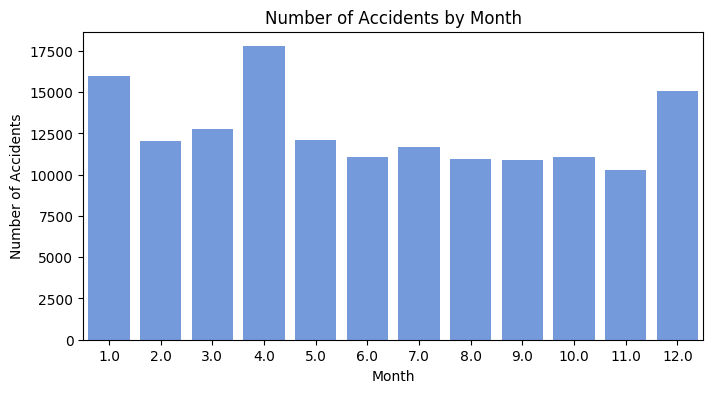

In [ ]:
#จำนวนอุบัติเหตุแยกตามเดือน(1-12)
plt.figure(figsize=(8,4))
sns.countplot(data=df_clean, x='month', color='cornflowerblue')
plt.title("Number of Accidents by Month")
plt.xlabel("Month")
plt.ylabel("Number of Accidents")
plt.show()

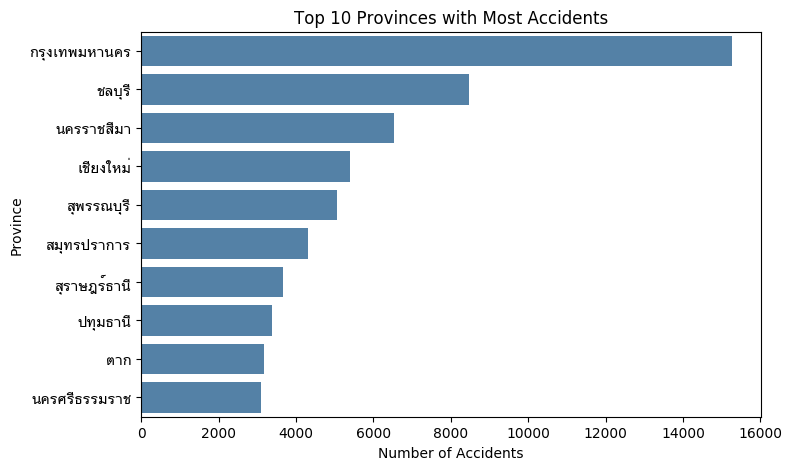

In [ ]:
#Top 10 จังหวัด (province) ที่เกิดอุบัติเหตุมากที่สุด
top10_prov = df_clean['province'].value_counts().head(10)

plt.figure(figsize=(8,5))
sns.barplot(x=top10_prov.values, y=top10_prov.index, color='steelblue')
plt.title("Top 10 Provinces with Most Accidents")
plt.xlabel("Number of Accidents")
plt.ylabel("Province")
plt.show()

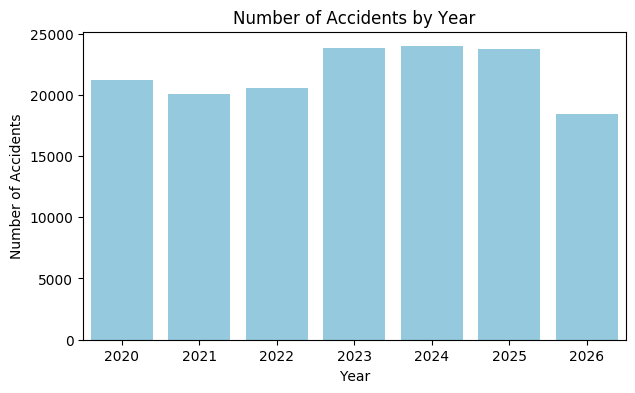

In [ ]:
#จำนวนอุบัติเหตุแยกตามปี
plt.figure(figsize=(7,4))
sns.countplot(data=df, x='accident_year', color='skyblue')
plt.title("Number of Accidents by Year")
plt.xlabel("Year")
plt.ylabel("Number of Accidents")
plt.show()

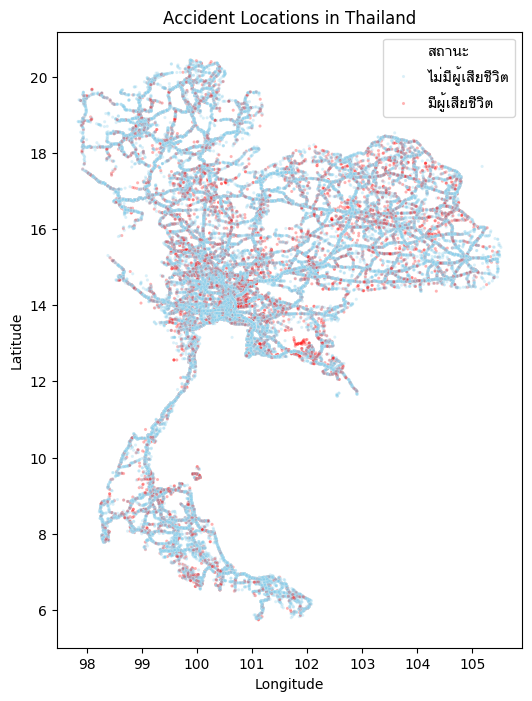

In [ ]:
#แผนที่จุดเกิดเหตุในประเทศไทย (longitude, latitude)
geo = df_clean[
    df_clean['latitude'].between(5.5, 20.6)
    & df_clean['longitude'].between(97.3, 105.7)
]


fatal_label = geo['is_fatal'].map({
    0: 'ไม่มีผู้เสียชีวิต',
    1: 'มีผู้เสียชีวิต'
})

plt.figure(figsize=(6, 8))
sns.scatterplot(
    data=geo,
    x='longitude',
    y='latitude',
    hue=fatal_label,
    s=5,
    alpha=0.3,
    palette={
        'ไม่มีผู้เสียชีวิต': 'skyblue',
        'มีผู้เสียชีวิต': 'red'
    }
)
plt.title("Accident Locations in Thailand")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(title="สถานะ")
plt.show()

In [ ]:
# 1. สร้างตัวแปร Target: 1 = รุนแรง (ตาย/สาหัส), 0 = ไม่รุนแรง
df_clean['is_severe'] = ((df_clean['fatality_count'] > 0) | (df_clean['serious_injury_count'] > 0)).astype(int)

# 2. ดึงชั่วโมง (0-23) ถ้ายังไม่ได้ทำ
df_clean['hour'] = pd.to_numeric(df_clean['accident_time'].astype(str).str.split(':').str[0], errors='coerce')

/tmp/ipykernel_4185/3078225013.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, x='is_severe', palette=['skyblue', 'salmon'])


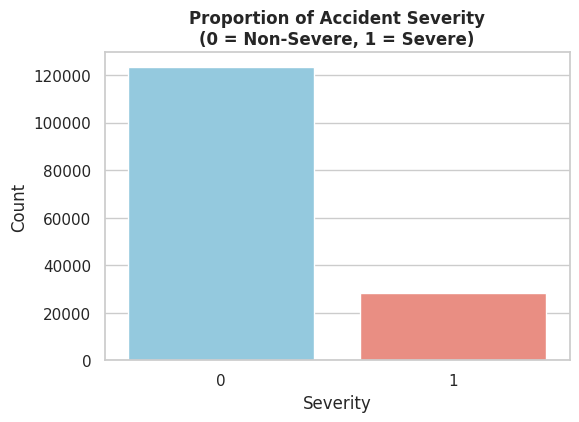

In [ ]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df_clean, x='is_severe', palette=['skyblue', 'salmon'])
plt.title("Proportion of Accident Severity\n(0 = Non-Severe, 1 = Severe)")
plt.xlabel("Severity")
plt.ylabel("Count")
plt.show()

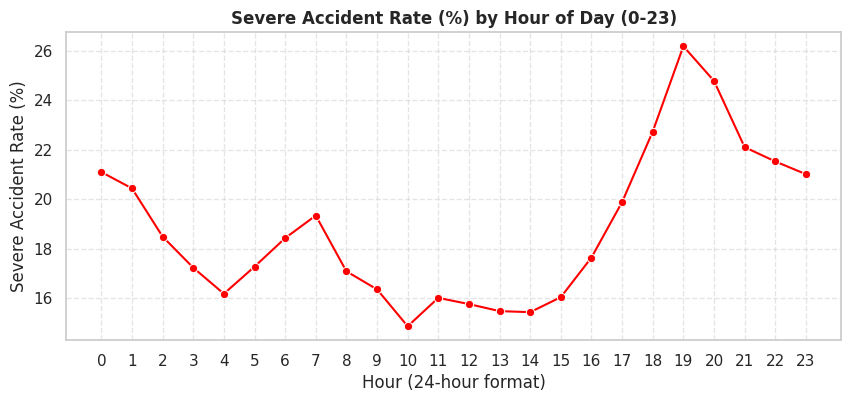

In [ ]:
plt.figure(figsize=(10, 4))
# หาค่าเฉลี่ยของ is_severe ในแต่ละชั่วโมง (เท่ากับหา % ความรุนแรง)
hourly_severe = df_clean.groupby('hour')['is_severe'].mean() * 100

sns.lineplot(x=hourly_severe.index, y=hourly_severe.values, marker='o', color='red')
plt.title("Severe Accident Rate (%) by Hour of Day (0-23)")
plt.xlabel("Hour (24-hour format)")
plt.ylabel("Severe Accident Rate (%)")
plt.xticks(range(0, 24))
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

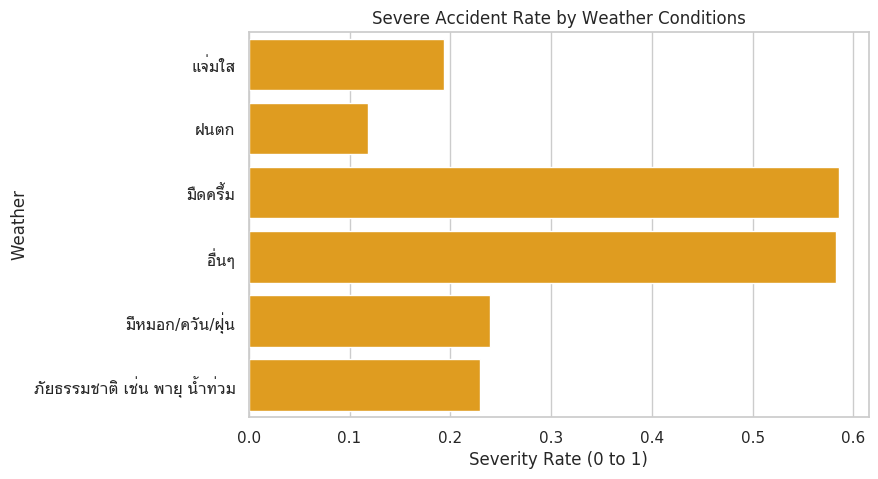

In [ ]:
plt.figure(figsize=(8, 5))
# เลือกเฉพาะสภาพอากาศที่ไม่ใช่ 'Unknown'
weather_data = df_clean[df_clean['weather'] != 'Unknown']

sns.barplot(data=weather_data, x='is_severe', y='weather', estimator=np.mean, color='orange', errorbar=None)
plt.title("Severe Accident Rate by Weather Conditions")
plt.xlabel("Severity Rate (0 to 1)")
plt.ylabel("Weather")
plt.show()

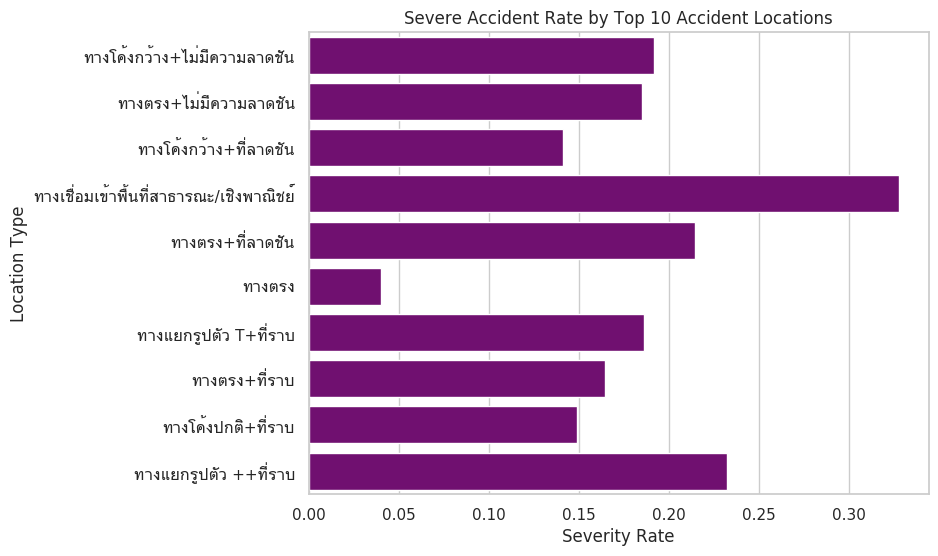

In [ ]:
plt.figure(figsize=(8, 6))
# เลือก 10 ลักษณะจุดเกิดเหตุที่เกิดบ่อยที่สุด
top_locations = df_clean['accident_location'].value_counts().nlargest(10).index
loc_data = df_clean[df_clean['accident_location'].isin(top_locations)]

sns.barplot(data=loc_data, y='accident_location', x='is_severe', color='purple', errorbar=None)
plt.title("Severe Accident Rate by Top 10 Accident Locations")
plt.xlabel("Severity Rate")
plt.ylabel("Location Type")
plt.show()

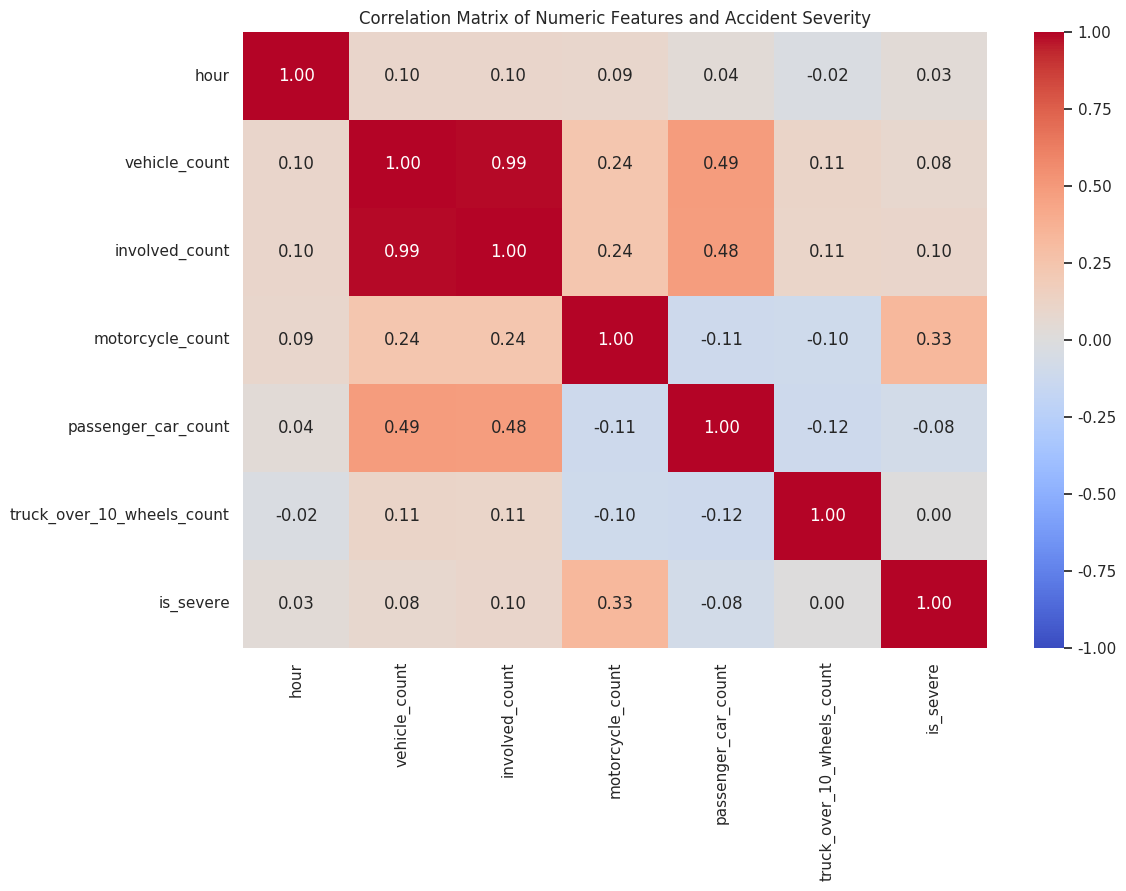

In [ ]:
plt.figure(figsize=(12, 8))
# เลือกเฉพาะตัวแปรที่เป็นตัวเลขและไม่เกิด Data Leakage
num_cols = ['hour', 'vehicle_count', 'involved_count', 'motorcycle_count',
            'passenger_car_count', 'truck_over_10_wheels_count', 'is_severe']

# คำนวณ Correlation Matrix
corr_matrix = df_clean[num_cols].corr()

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Matrix of Numeric Features and Accident Severity")
plt.show()

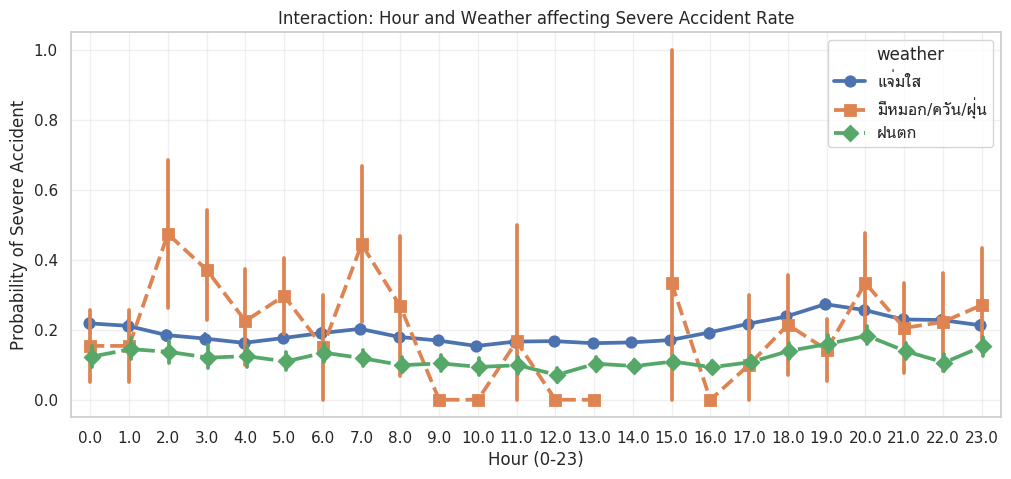

In [ ]:
plt.figure(figsize=(12, 5))
# กรองเอาสภาพอากาศที่พบบ่อย 3 อันดับแรกเพื่อไม่ให้กราฟรกเกินไป
top_weather = df_clean['weather'].value_counts().nlargest(3).index
df_weather = df_clean[df_clean['weather'].isin(top_weather)]

sns.pointplot(data=df_weather, x='hour', y='is_severe', hue='weather',
              dodge=True, markers=['o', 's', 'D'], linestyles=['-', '--', '-.'])
plt.title("Interaction: Hour and Weather affecting Severe Accident Rate")
plt.xlabel("Hour (0-23)")
plt.ylabel("Probability of Severe Accident")
plt.grid(True, alpha=0.3)
plt.show()

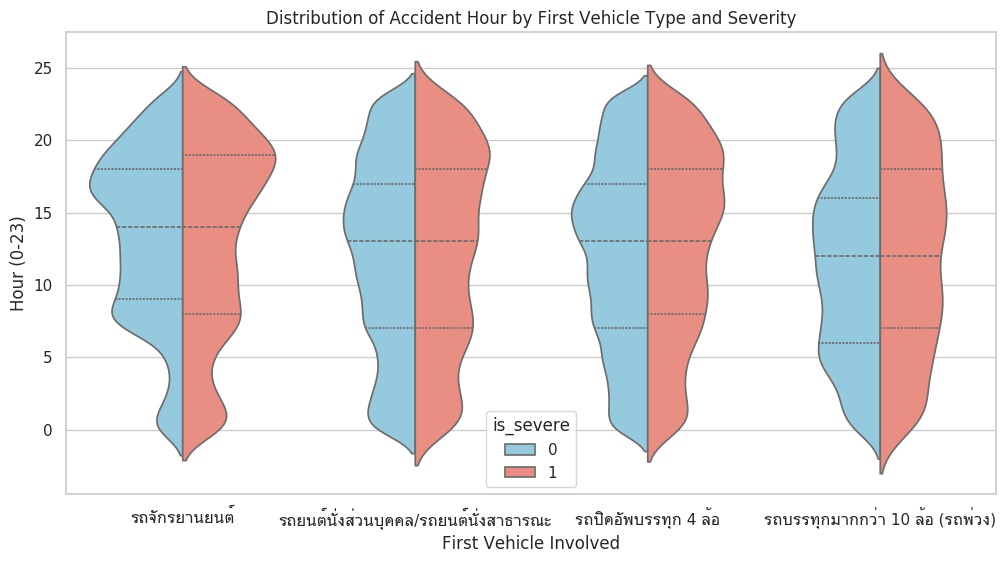

In [ ]:
plt.figure(figsize=(12, 6))
# เลือกยานพาหนะหลัก 4 ประเภท
top_vehicles = df_clean['first_vehicle'].value_counts().nlargest(4).index
df_veh = df_clean[df_clean['first_vehicle'].isin(top_vehicles)]

sns.violinplot(data=df_veh, x='first_vehicle', y='hour', hue='is_severe',
               split=True, inner="quart", palette=['skyblue', 'salmon'])
plt.title("Distribution of Accident Hour by First Vehicle Type and Severity")
plt.xlabel("First Vehicle Involved")
plt.ylabel("Hour (0-23)")
plt.show()

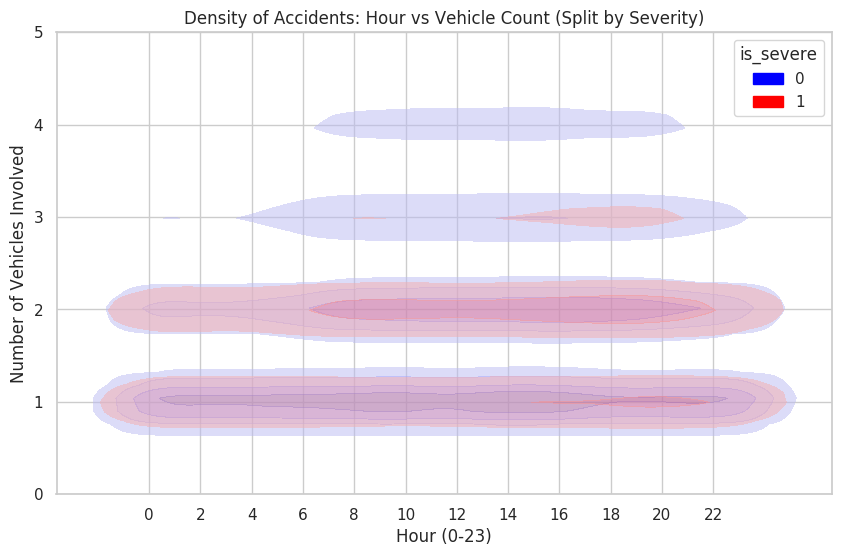

In [ ]:
plt.figure(figsize=(10, 6))
# พล็อต Contour (KDE) แยกสีตามความรุนแรง
sns.kdeplot(data=df_clean, x='hour', y='vehicle_count', hue='is_severe',
            fill=True, alpha=0.5, levels=5, palette=['blue', 'red'])
plt.title("Density of Accidents: Hour vs Vehicle Count (Split by Severity)")
plt.xlabel("Hour (0-23)")
plt.ylabel("Number of Vehicles Involved")
plt.ylim(0, 5) # จำกัดแกน Y เพื่อให้เห็นภาพชัดเจนขึ้น (กรณีส่วนใหญ่รถ 1-5 คัน)
plt.xticks(range(0, 24, 2))
plt.show()

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder

# เตรียมข้อมูลแบบไวๆ ตัด Missing values และเลือกเฉพาะ Features ที่สนใจ
features = ['hour', 'month', 'vehicle_count', 'province', 'accident_location', 'weather', 'first_vehicle']
df_rf = df_clean.dropna(subset=features + ['is_severe']).copy()

# แปลงตัวแปรหมวดหมู่เป็นตัวเลขชั่วคราวเพื่อให้รัน Tree ได้
le = LabelEncoder()
for col in ['province', 'accident_location', 'weather', 'first_vehicle']:
    df_rf[col] = le.fit_transform(df_rf[col].astype(str))

X = df_rf[features]
y = df_rf['is_severe']

# เทรน Random Forest เบื้องต้น
rf = RandomForestClassifier(n_estimators=100, random_state=42, max_depth=5)
rf.fit(X, y)

# นำความสำคัญของตัวแปรมาสร้าง Dataframe และพล็อตกราฟ
importance_df = pd.DataFrame({'Feature': features, 'Importance': rf.feature_importances_})
importance_df = importance_df.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=importance_df, x='Importance', y='Feature', palette='viridis')
plt.title("Feature Importance in Predicting Accident Severity (Random Forest)")
plt.xlabel("Relative Importance")
plt.ylabel("Features")
plt.show()